[![Roboflow Notebooks](https://media.roboflow.com/notebooks/template/bannertest2-2.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672932710194)](https://github.com/roboflow/notebooks)

# How to Train YOLO26 Instance Segmentation on a Custom Dataset

---

[![roboflow](https://raw.githubusercontent.com/roboflow-ai/notebooks/main/assets/badges/roboflow-blogpost.svg)](https://blog.roboflow.com/train-yolo26-instance-segmentation-custom-data/) [![GitHub](https://badges.aleen42.com/src/github.svg)](https://github.com/ultralytics/ultralytics)

YOLO26 introduces a unified architecture designed to support detection, segmentation, and pose tasks within a single model family. The model uses an anchor-free design with a decoupled head.

## Setup

### Configure API keys

To fine-tune YOLO26, you need to provide your Roboflow API key. Follow these steps:

- Go to your [`Roboflow Settings`](https://app.roboflow.com/settings/api) page. Click `Copy`. This will place your private key in the clipboard.
- In Colab, go to the left pane and click on `Secrets` (🔑). Store Roboflow API Key under the name `ROBOFLOW_API_KEY`.

### Before you start

Let's make sure that we have access to GPU. We can use `nvidia-smi` command to do that. In case of any problems navigate to `Runtime` -> `Change runtime type` -> `Hardware accelerator`, set it to `GPU`, and then click `Save`.

In [12]:
!nvidia-smi

Mon Nov  2 12:29:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

**NOTE:** To make it easier for us to manage datasets, images and models we create a `HOME` constant.

In [13]:
import os
HOME = os.getcwd()
print(HOME)

/content


### Install dependencies required for YOLO26

In [14]:
%pip install -q "ultralytics>=8.4.0" supervision roboflow

# prevent ultralytics from tracking your activity
!yolo settings sync=False
import ultralytics
ultralytics.checks()

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.3/112.6 GB disk)


In [38]:
!yolo checks

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 1.0/112.6 GB disk)

OS                     Linux-6.6.159+-x86_64-with-glibc2.39
Environment            Colab
Python                 3.13.16
Install                pip
Path                   /usr/local/lib/python3.13/dist-packages/ultralytics
RAM                    12.67 GB
Disk                   1.0/112.6 GB
CPU                    Intel Xeon CPU @ 2.00GHz
CPU count              2
GPU                    Tesla T4, 14913MiB
GPU count              1
CUDA                   13.0

numpy                  ✅ 2.1.3>=1.23.0; platform_system != "Darwin"
numpy                  ✅ 2.1.3!=2.0.*,!=2.1.*,!=2.2.*,!=2.3.0,!=2.3.1,!=2.3.2,!=2.3.3,!=2.3.4,>=1.23.0; platform_system == "Darwin"
matplotlib             ✅ 3.10.0>=3.3.0
opencv-python          ✅ 5.0.0.93!=4.13.0.90,>=4.7.0
pillow                 ✅ 11.3.0>=7.1.2
requests               ✅ 2.32.4>=2.23.0
torch                  ✅ 2.

### Download example data

Downloads example images for testing. You can use these or replace them with your own images.

In [35]:
!wget -q https://github.com/de-beavers/DE_etc/tree/main/notebooks/examples/img_1.jpg
!wget -q https://github.com/de-beavers/DE_etc/tree/main/notebooks/examples/img_2.jpg
!wget -q https://github.com/de-beavers/DE_etc/tree/main/notebooks/examples/img_3.jpg

## Inference with model pre-trained on COCO dataset

### CLI

**NOTE:** CLI requires no customization or Python code. You can simply run all tasks from the terminal with the yolo command.

In [ ]:
!yolo task=segment mode=predict model=yolo26m-seg.pt source={HOME}/img_1.jpg save=True verbose=False

Ultralytics 8.4.6 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLO26m-seg summary (fused): 149 layers, 23,569,148 parameters, 0 gradients, 121.5 GFLOPs
Results saved to /content/runs/segment/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


**NOTE:** Result annotated image got saved in `{HOME}/runs/segment/predict/`. Let's display it.

In [16]:
!ls -la {HOME}/runs/segment/predict/

ls: cannot access '/content/runs/segment/predict/': No such file or directory


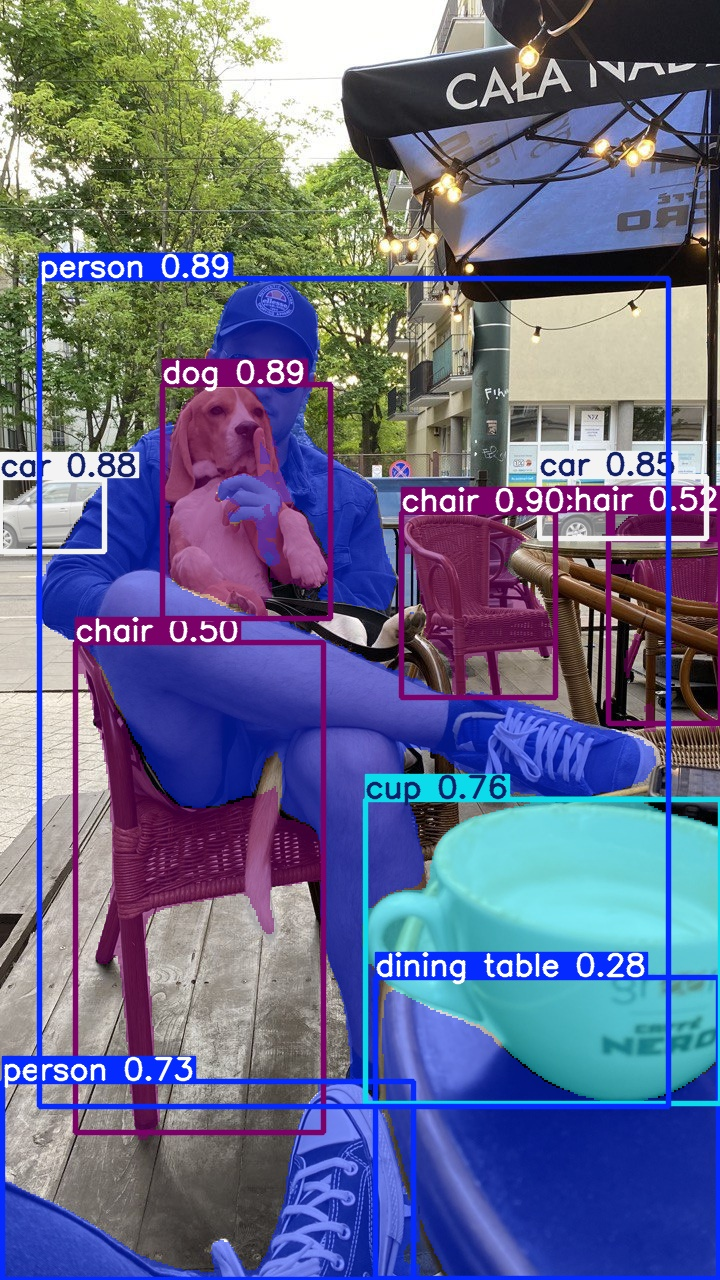

In [ ]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/predict/dog-3.jpg', width=600)

### SDK

**NOTE:** YOLO's Python interface allows for seamless integration into your Python projects, making it easy to load, run, and process the model's output.

In [ ]:
from ultralytics import YOLO
from PIL import Image
import requests

model = YOLO('yolo26m-seg.pt')
image = Image.open(f'{HOME}/img_1.jpg')
result = model.predict(image, verbose=False)[0]

**NOTE:** The obtained `result` object stores information about the location, classes, and confidence levels of the detected objects.

In [ ]:
result.boxes.xyxy

tensor([[4.0182e+02, 5.1232e+02, 5.5529e+02, 6.9761e+02],
        [3.9843e+01, 2.7866e+02, 6.6899e+02, 1.1064e+03],
        [1.6295e+02, 3.8428e+02, 3.3045e+02, 6.1896e+02],
        [1.1827e-01, 4.7719e+02, 1.0477e+02, 5.5199e+02],
        [5.3914e+02, 4.7685e+02, 7.0694e+02, 5.3834e+02],
        [3.6556e+02, 7.9963e+02, 7.2000e+02, 1.1036e+03],
        [2.1371e+00, 1.0812e+03, 4.1310e+02, 1.2793e+03],
        [6.1278e+02, 5.1156e+02, 7.1909e+02, 5.3960e+02],
        [7.5835e+01, 6.4234e+02, 3.2344e+02, 1.1328e+03],
        [6.0898e+02, 5.1196e+02, 7.2000e+02, 7.2374e+02],
        [3.7518e+02, 9.7783e+02, 7.1856e+02, 1.2789e+03]], device='cuda:0')

In [ ]:
result.boxes.conf

tensor([0.8982, 0.8916, 0.8912, 0.8809, 0.8510, 0.7554, 0.7347, 0.5185, 0.5021, 0.3332, 0.2773], device='cuda:0')

In [ ]:
result.boxes.cls

tensor([56.,  0., 16.,  2.,  2., 41.,  0., 56., 56., 56., 60.], device='cuda:0')

In [ ]:
result.masks.data.shape

torch.Size([11, 640, 384])

**NOTE:** YOLO26 can be easily integrated with `supervision` using the familiar `from_ultralytics` connector.

In [ ]:
import supervision as sv

detections = sv.Detections.from_ultralytics(result)

In [ ]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    mask_annotator = sv.MaskAnnotator()
    polygon_annotator = sv.PolygonAnnotator(color=sv.Color.WHITE)
    label_annotator = sv.LabelAnnotator(
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        text_position=sv.Position.CENTER_OF_MASS
    )

    out = image.copy()
    out = mask_annotator.annotate(out, detections)
    out = polygon_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

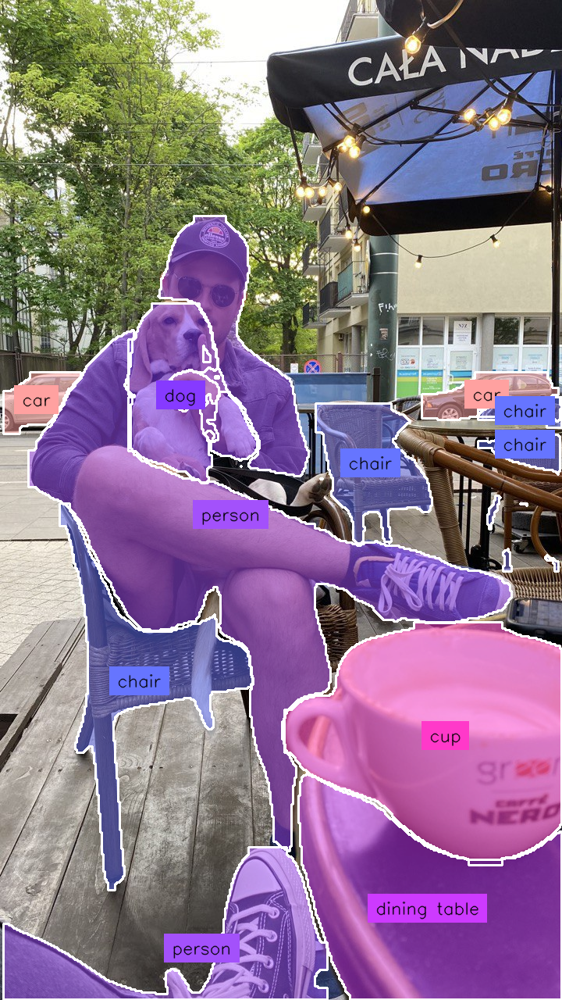

In [ ]:
annotated_image = annotate(image, detections)
annotated_image

## Fine-tune YOLO26 on custom dataset

**NOTE:** When training YOLO26, make sure your data is located in `datasets`. If you'd like to change the default location of the data you want to use for fine-tuning, you can do so through Ultralytics' `settings.json`. In this tutorial, we will use one of the [datasets](https://universe.roboflow.com/liangdianzhong/-qvdww) available on [Roboflow Universe](https://universe.roboflow.com/). When downloading, make sure to select the `yolov11` export format.

In [23]:
!mkdir {HOME}/datasets
%cd {HOME}/datasets

from google.colab import userdata
from roboflow import Roboflow

ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

workspace = rf.workspace("dmitry-g")
project = workspace.project("dacl10k_mini_nt_chk")
version = project.version(1)
dataset = version.download("yolo26")

mkdir: cannot create directory ‘/content/datasets’: File exists
/content/datasets
loading Roboflow workspace...
loading Roboflow project...
Exporting format yolo26 in progress : 95.0%
Version export complete for yolo26 format



Extracting Dataset Version Zip to dacl10k_mini_nt_chk-1 in yolo26:: 100%|██████████| 1298/1298 [00:00<00:00, 1941.23it/s]


## Custom Training

In [71]:
%cd {HOME}

!yolo task=segment mode=train model=yolo26n-seg.pt data={dataset.location}/data.yaml epochs=20 imgsz=640 plots=True #freeze=11

/content
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/dacl10k_mini_nt_chk-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-9, nbs=64, nms=None, 

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

In [72]:
!ls {HOME}/runs/segment/train-9/

args.yaml			 MaskP_curve.png     train_batch361.jpg
BoxF1_curve.png			 MaskPR_curve.png    train_batch362.jpg
BoxP_curve.png			 MaskR_curve.png     val_batch0_labels.jpg
BoxPR_curve.png			 results.csv	     val_batch0_pred.jpg
BoxR_curve.png			 results.png	     val_batch1_labels.jpg
confusion_matrix_normalized.png  train_batch0.jpg    val_batch1_pred.jpg
confusion_matrix.png		 train_batch1.jpg    val_batch2_labels.jpg
labels.jpg			 train_batch2.jpg    val_batch2_pred.jpg
MaskF1_curve.png		 train_batch360.jpg  weights


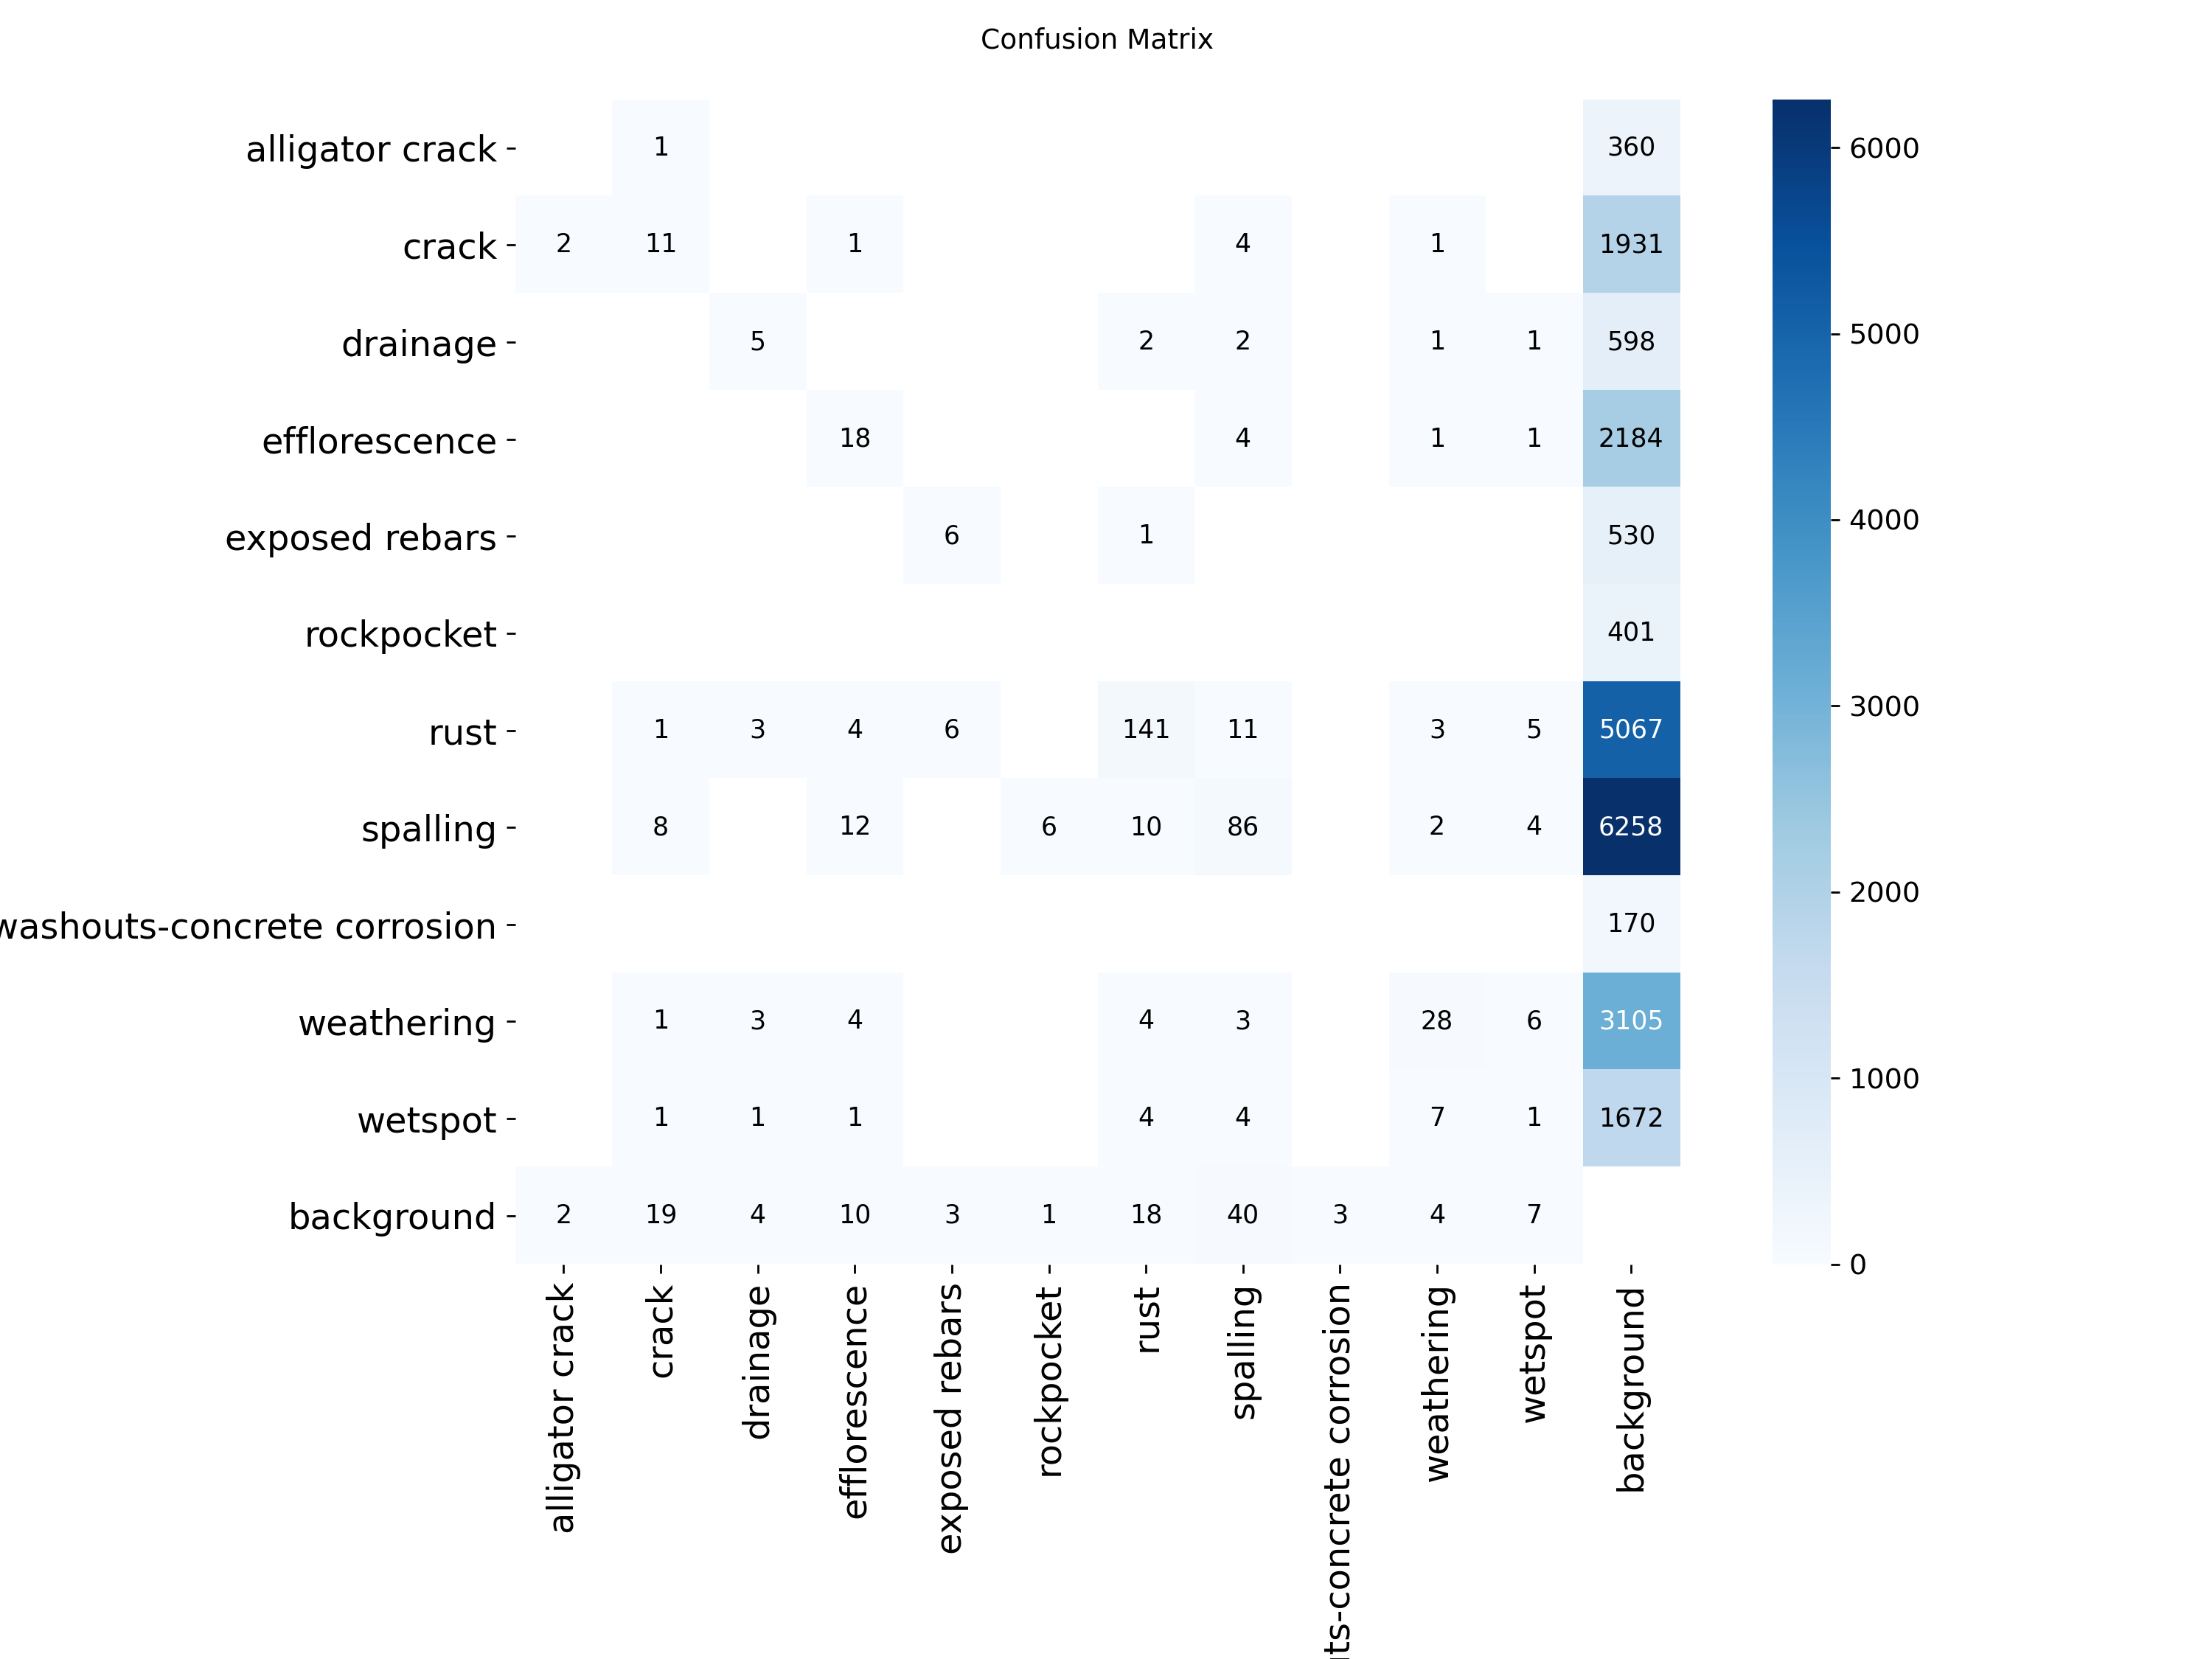

In [73]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train-9/confusion_matrix.png', width=1000)

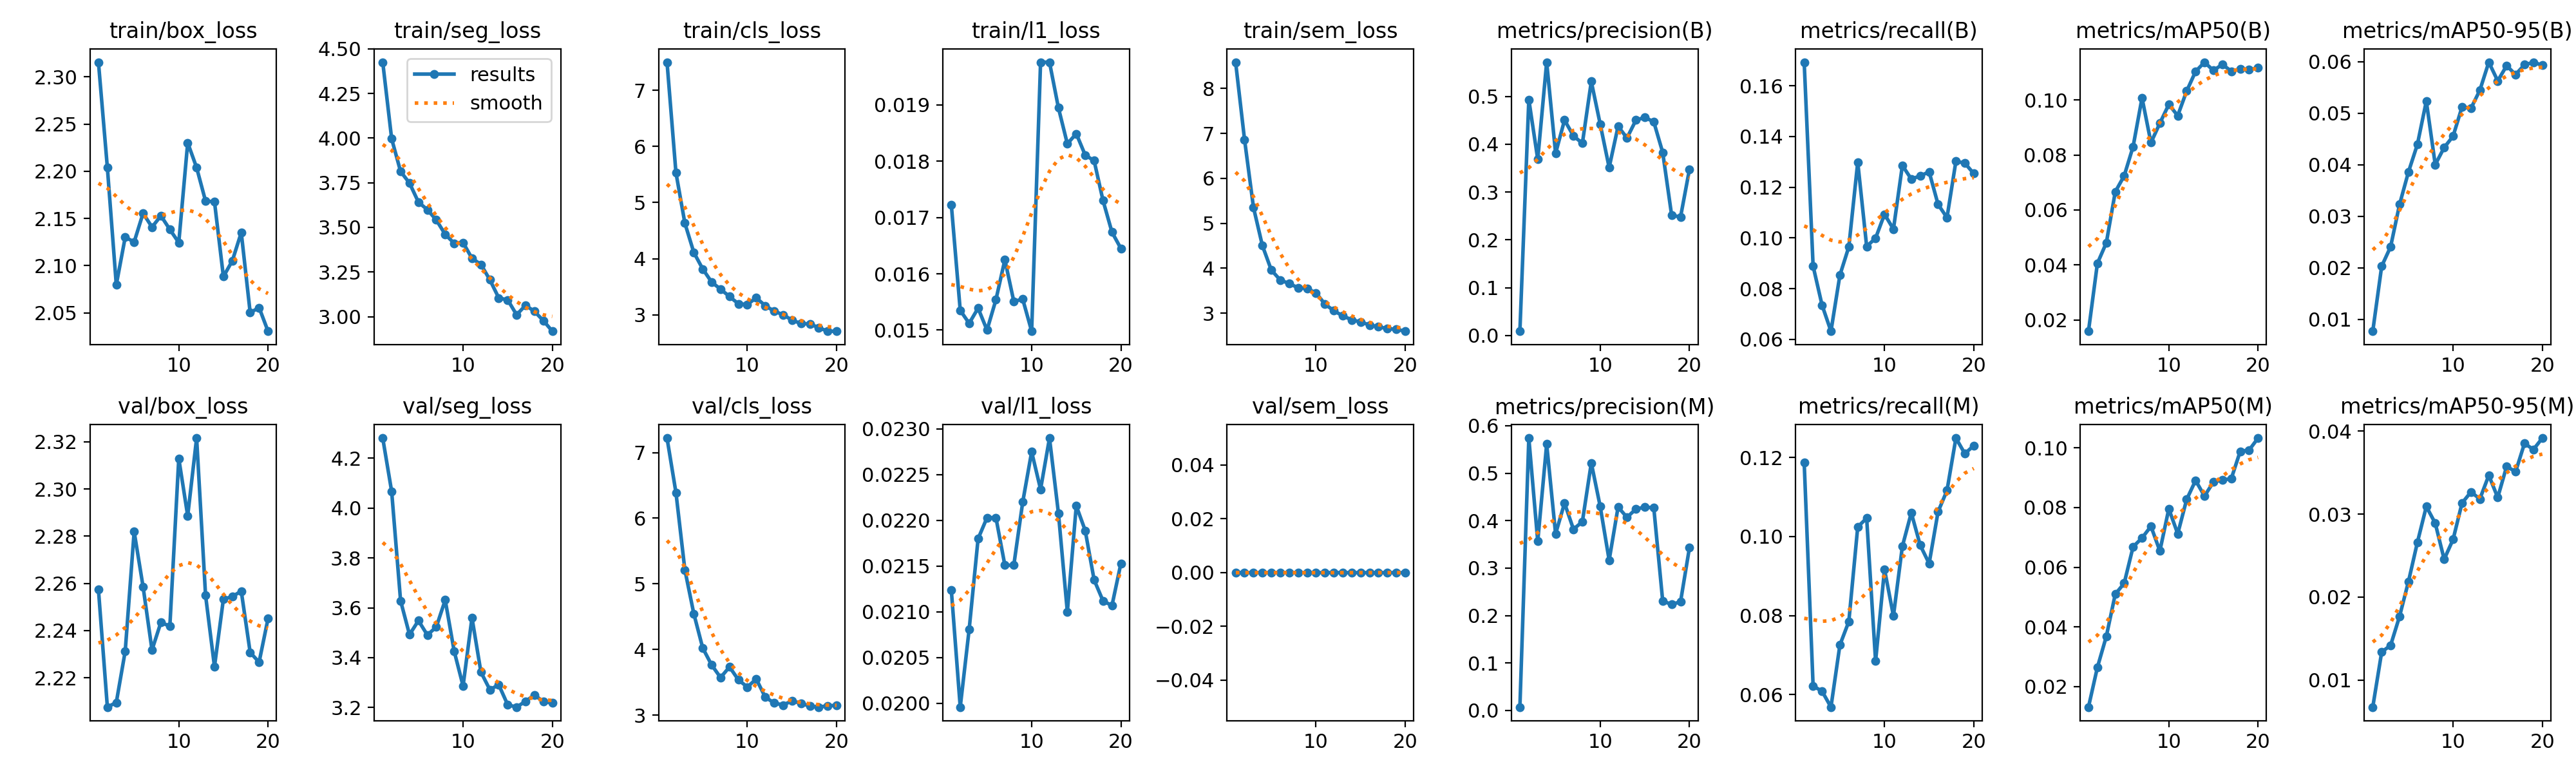

In [74]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train-9/results.png', width=1000)

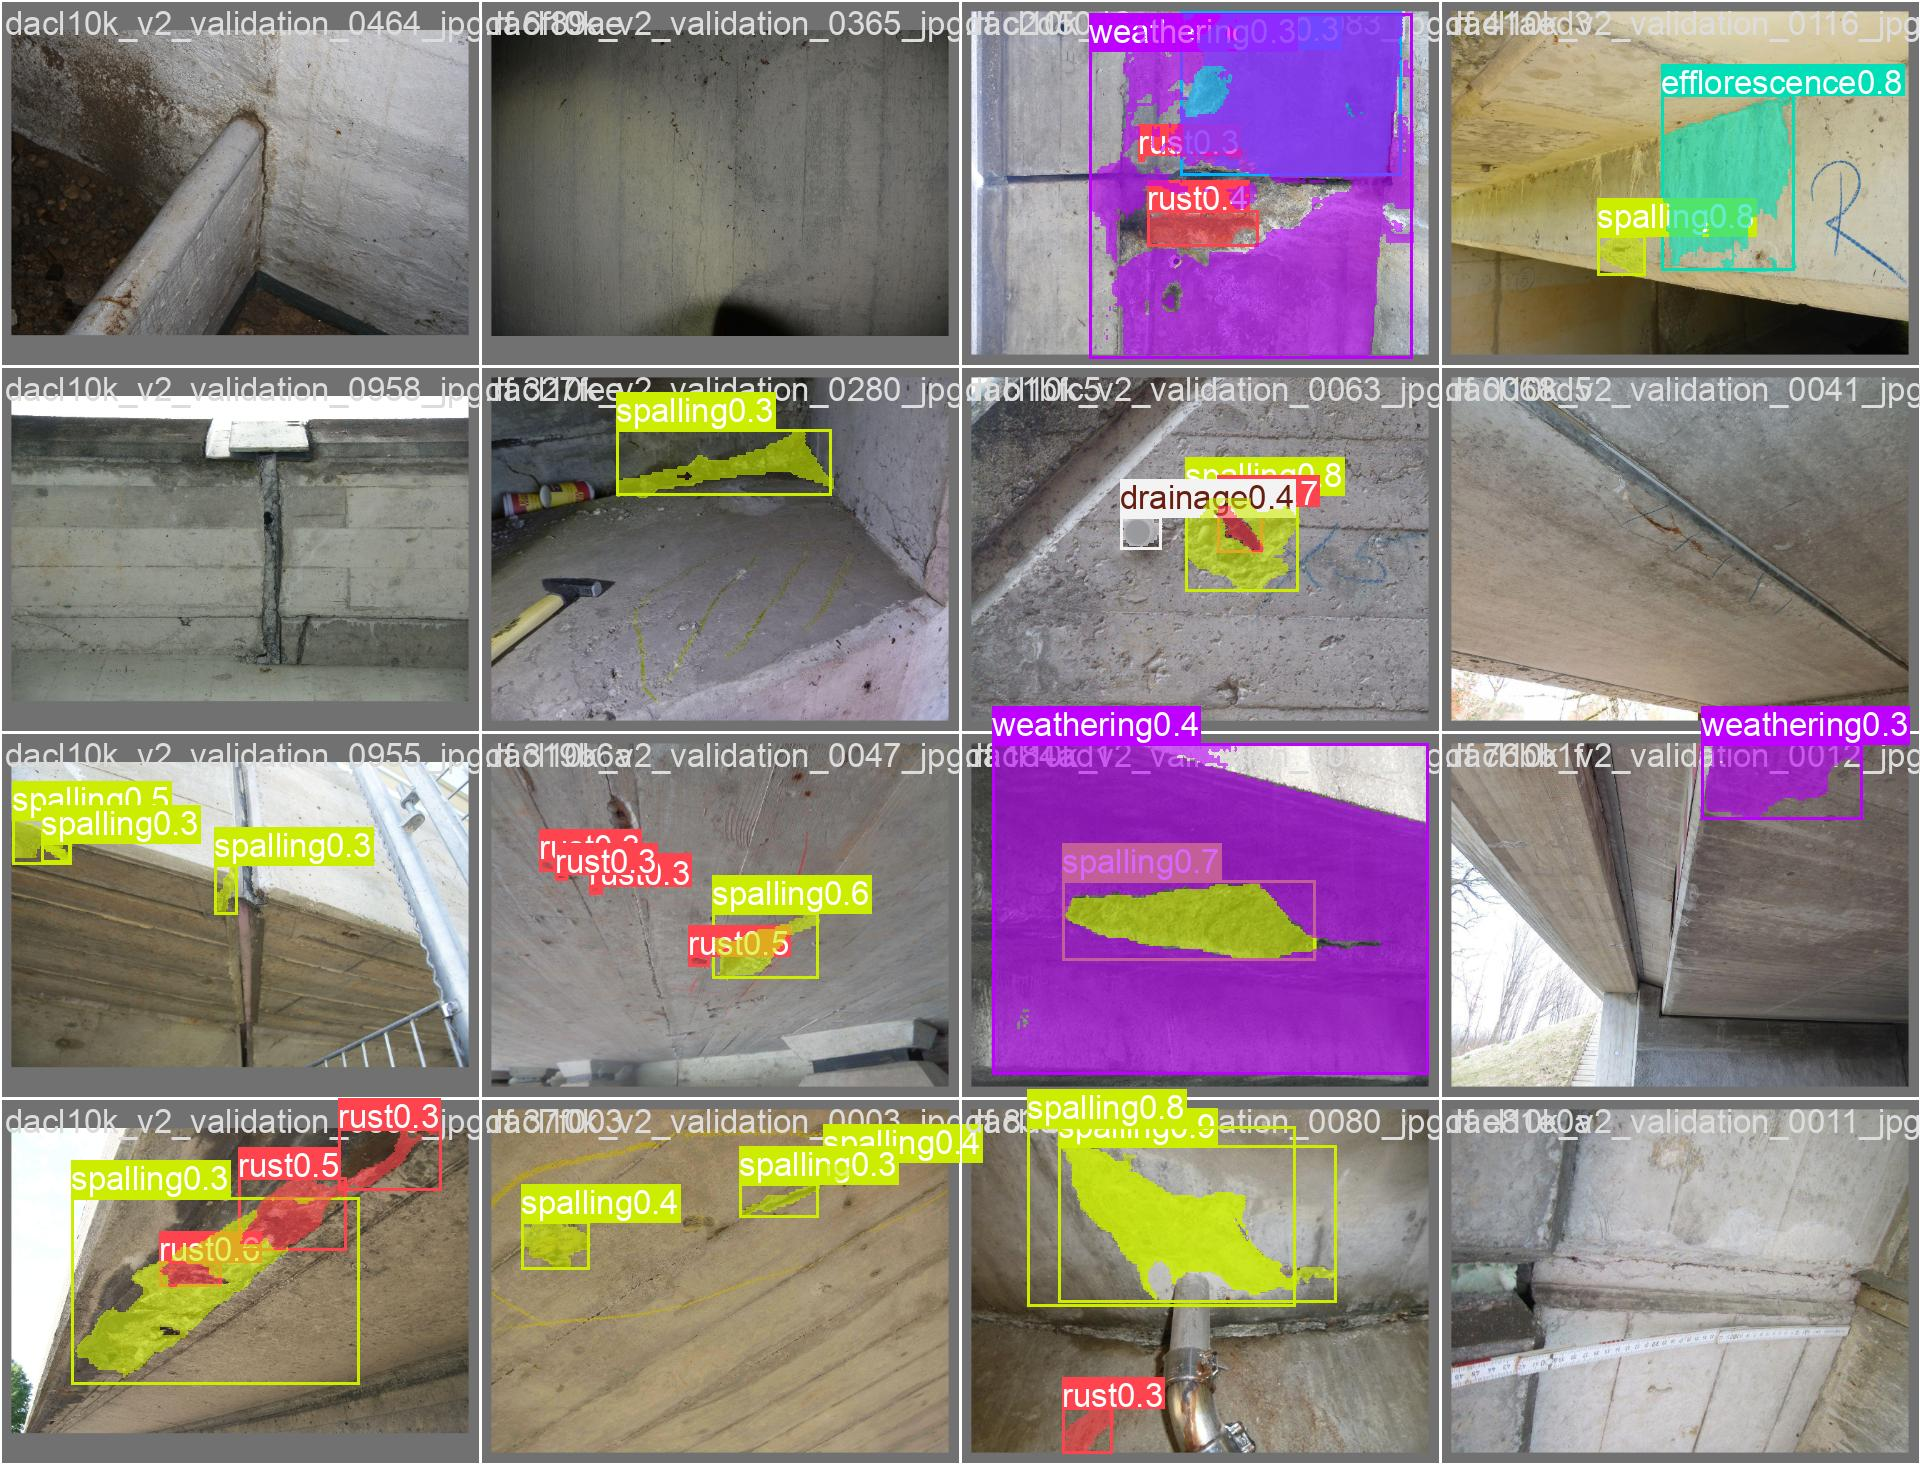

In [75]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'{HOME}/runs/segment/train-9/val_batch0_pred.jpg', width=2000)

## Validate fine-tuned model

In [61]:
!yolo task=segment mode=val model={HOME}/runs/segment/train-8/weights/best.pt data={dataset.location}/data.yaml

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-seg summary (fused): 137 layers, 2,706,213 parameters, 0 gradients, 9.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 141.1±74.4 MB/s, size: 644.7 KB)
val: Scanning /content/datasets/dacl10k_mini_nt_chk-1/valid/labels.cache... 81 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 81/81 8.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.1s/it 12.7s
                   all         81        543      0.386      0.116     0.0897     0.0472      0.418     0.0741     0.0678     0.0284
       alligator crack          4          4          1          0          0          0          1          0          0          0
                 crack         29         42      0.121      0.119     0.0474     0.0119      0.136     0.0476     0.0273    0.00669
              drainage   

## Inference with custom model

### CLI

In [30]:
!yolo task=segment mode=predict model={HOME}/runs/segment/train/weights/best.pt source={dataset.location}/test/images save=True verbose=False

Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26x-seg summary (fused): 204 layers, 62,739,437 parameters, 0 gradients, 313.6 GFLOPs
Traceback (most recent call last):
  File "/usr/local/bin/yolo", line 6, in <module>
    sys.exit(entrypoint())
             ~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/cfg/__init__.py", line 1190, in entrypoint
    getattr(model, mode)(**overrides)  # default args from model
    ~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/model.py", line 571, in predict
    return self.predictor.predict_cli(source=source) if is_cli else self.predictor(source=source, stream=stream)
           ~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/ultralytics/engine/predictor.py", line 286, in predict_cli
    for _ in gen:  # sourcery skip: remove-empty-nested-block, noqa
             ^^^
  File "/usr/local/lib/py

### SDK

In [62]:
from ultralytics import YOLO

model = YOLO(f'{HOME}/runs/segment/train-8/weights/best.pt')

In [63]:
import supervision as sv

ds_test = sv.DetectionDataset.from_yolo(
    images_directory_path=f"{dataset.location}/test/images",
    annotations_directory_path=f"{dataset.location}/test/labels",
    data_yaml_path=f"{dataset.location}/data.yaml",
    force_masks=True
)

In [64]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    color = sv.ColorPalette.from_hex([
        "#9999ff", "#3399ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00",
        "#ffff00", "#ff9b00", "#ff8080", "#ff66b2", "#ff66ff", "#b266ff",
    ])

    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    mask_annotator = sv.MaskAnnotator()
    polygon_annotator = sv.PolygonAnnotator(color=sv.Color.WHITE)
    label_annotator = sv.LabelAnnotator(
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        text_position=sv.Position.CENTER_OF_MASS
    )

    out = image.copy()
    out = mask_annotator.annotate(out, detections)
    out = polygon_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

In [69]:
import random
import matplotlib.pyplot as plt

N = 9
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model.predict(image, verbose=False)[0]
    detections = sv.Detections.from_ultralytics(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

ValueError: Sample larger than population or is negative

In [70]:
annotated_images[0]

IndexError: list index out of range

## Deploy model on Roboflow

Upload the YOLO26 weights to Roboflow Deploy for inference on Roboflow infrastructure built for scale.

In [ ]:
project.version(dataset.version).deploy(model_type="yolo26", model_path=f"{HOME}/runs/segment/train/")

View the status of your deployment at: https://app.roboflow.com/roboflow-jvuqo/car-part-detection-with-damage-part-ubaii/4


## Run inference with a Roboflow hosted model

Load a trained model from Roboflow and run inference.

In [ ]:
!pip install -q inference

In [ ]:
from inference import get_model
from google.colab import userdata

ROBOFLOW_API_KEY = userdata.get('ROBOFLOW_API_KEY')

model_id = project.id.split("/")[1] + "/" + dataset.version
model = get_model(model_id, ROBOFLOW_API_KEY)

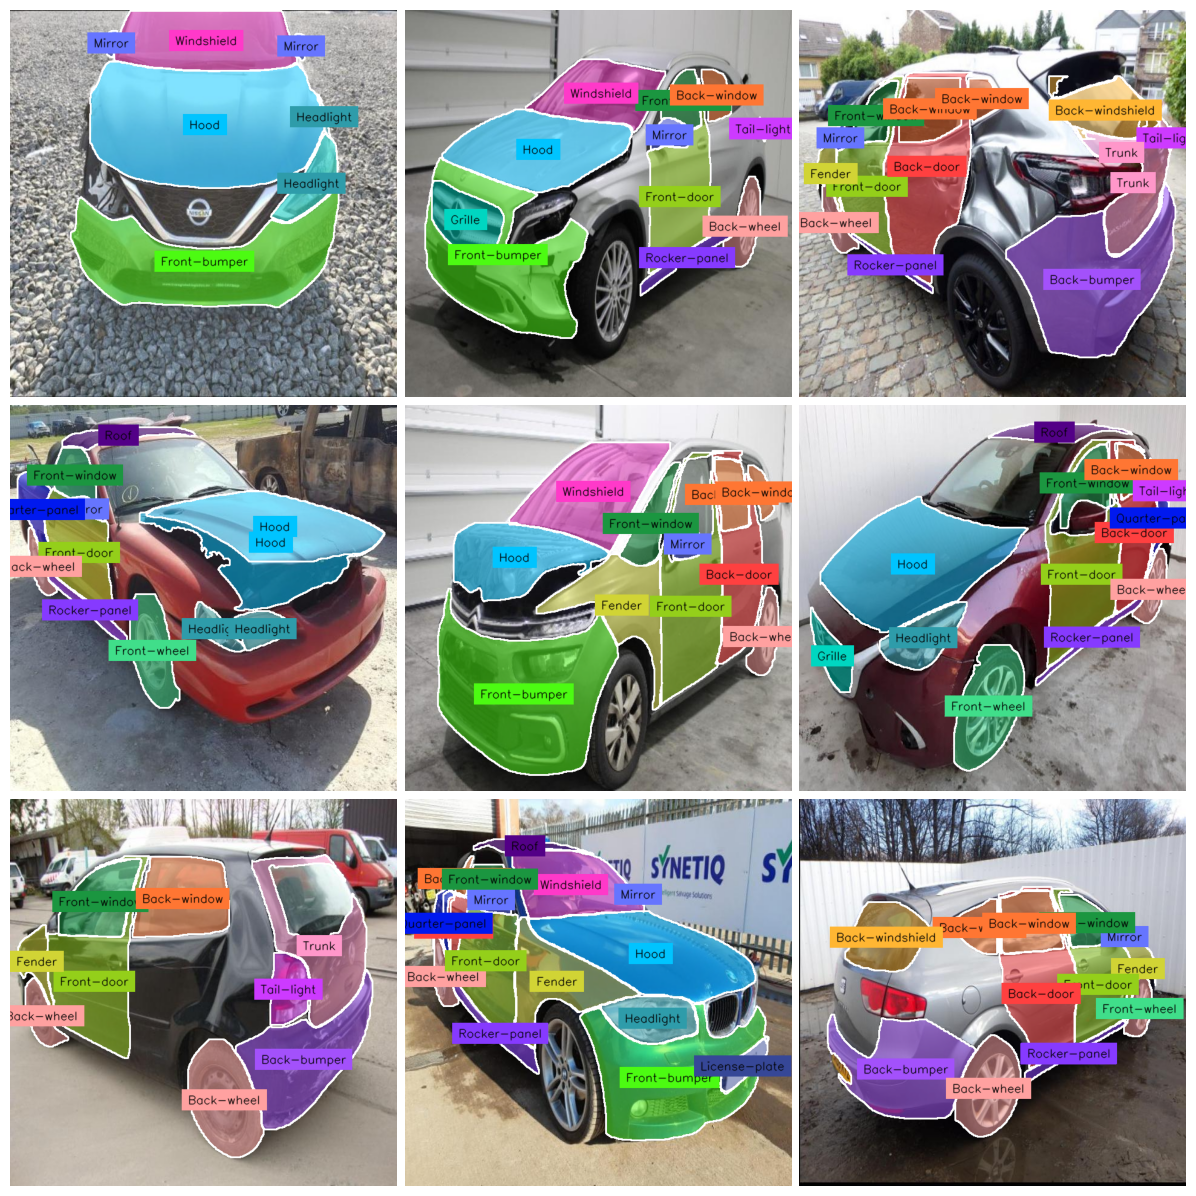

In [ ]:
import random
import matplotlib.pyplot as plt

N = 9
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model.infer(image)[0]
    detections = sv.Detections.from_inference(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

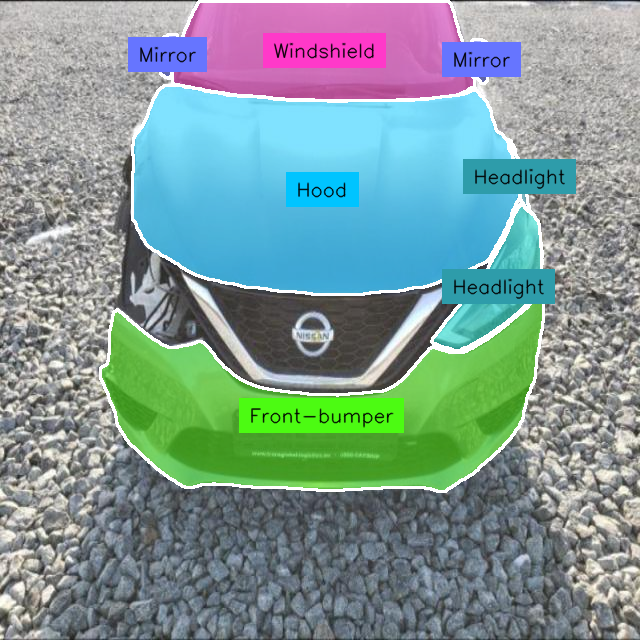

In [ ]:
annotated_images[0]

<div align="center">
  <p>
    Looking for more tutorials or have questions?
    Check out our <a href="https://github.com/roboflow/notebooks">GitHub repo</a> for more notebooks,
    or visit our <a href="https://discord.gg/GbfgXGJ8Bk">discord</a>.
  </p>
  
  <p>
    <strong>If you found this helpful, please consider giving us a ⭐
    <a href="https://github.com/roboflow/notebooks">on GitHub</a>!</strong>
  </p>

</div>